In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones y duraciones (en días) se adjunta.

In [3]:
pregunta_1 = "1. Dibuje el grafo Roy y calcule sobre él, actividad a actividad y en orden topológico, el inicio y el fin más tempranos: el inicio más temprano es el mayor de los fines más tempranos de las predecesoras.  "
pregunta_2 = "2. Calcule del mismo modo, de atrás hacia delante, los fines e inicios más tardíos.  "
pregunta_3 = "3. Para cada actividad con varias predecesoras indique cuál de ellas fija su inicio más temprano (la *predecesora dominante*). En particular, ¿qué predecesora de E manda?  "
pregunta_4 = "4. Si se quisiera adelantar el inicio de E un día, ¿qué actividad habría que acortar? ¿Serviría de algo acortar sus otras predecesoras?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje el grafo Roy y calcule sobre él, actividad a actividad y en orden topológico, el inicio y el fin más tempranos: el inicio más temprano es el mayor de los fines más tempranos de las predecesoras.  

2. Calcule del mismo modo, de atrás hacia delante, los fines e inicios más tardíos.  

3. Para cada actividad con varias predecesoras indique cuál de ellas fija su inicio más temprano (la *predecesora dominante*). En particular, ¿qué predecesora de E manda?  

4. Si se quisiera adelantar el inicio de E un día, ¿qué actividad habría que acortar? ¿Serviría de algo acortar sus otras predecesoras?  

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 4       ),
    ('B'     , '---'      , 6       ),
    ('C'     , '---'      , 1       ),
    ('D'     , 'A,B,C'    , 6       ),
    ('E'     , 'A,B,C'    , 3       ),
    ('F'     , 'D,E'      , 5       ),
    ('G'     , 'F'        , 4       ),
    ('H'     , 'G'        , 6       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_enunciado

,predecessor,duration
activity,,
A,---,4
B,---,6
C,---,1
D,"A,B,C",6
E,"A,B,C",3
F,"D,E",5
G,F,4
H,G,6


El proyecto corresponde a el lanzamiento de una aplicación móvil; las actividades son las siguientes (las duraciones del cuadro están en semanas).

In [5]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Estudio de requisitos',
    'B': 'Diseño de la arquitectura',
    'C': 'Diseño de interfaz y prototipo',
    'D': 'Base de datos y modelo',
    'E': 'API del servidor',
    'F': 'Pantallas principales',
    'G': 'Módulo de pagos',
    'H': 'Notificaciones y sincronización',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Estudio de requisitos
B,Diseño de la arquitectura
C,Diseño de interfaz y prototipo
D,Base de datos y modelo
E,API del servidor
F,Pantallas principales
G,Módulo de pagos
H,Notificaciones y sincronización


# Resolución

In [6]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
predecesoras = prelaciones.immediate_predecessor
sucesoras = {a: sorted(s for s, ps in predecesoras.items() if a in ps) for a in datos_proyecto.index}
duracion = datos_proyecto['duration']

## Apartado 1

In [7]:
display(Markdown(pregunta_1))

1. Dibuje el grafo Roy y calcule sobre él, actividad a actividad y en orden topológico, el inicio y el fin más tempranos: el inicio más temprano es el mayor de los fines más tempranos de las predecesoras.  

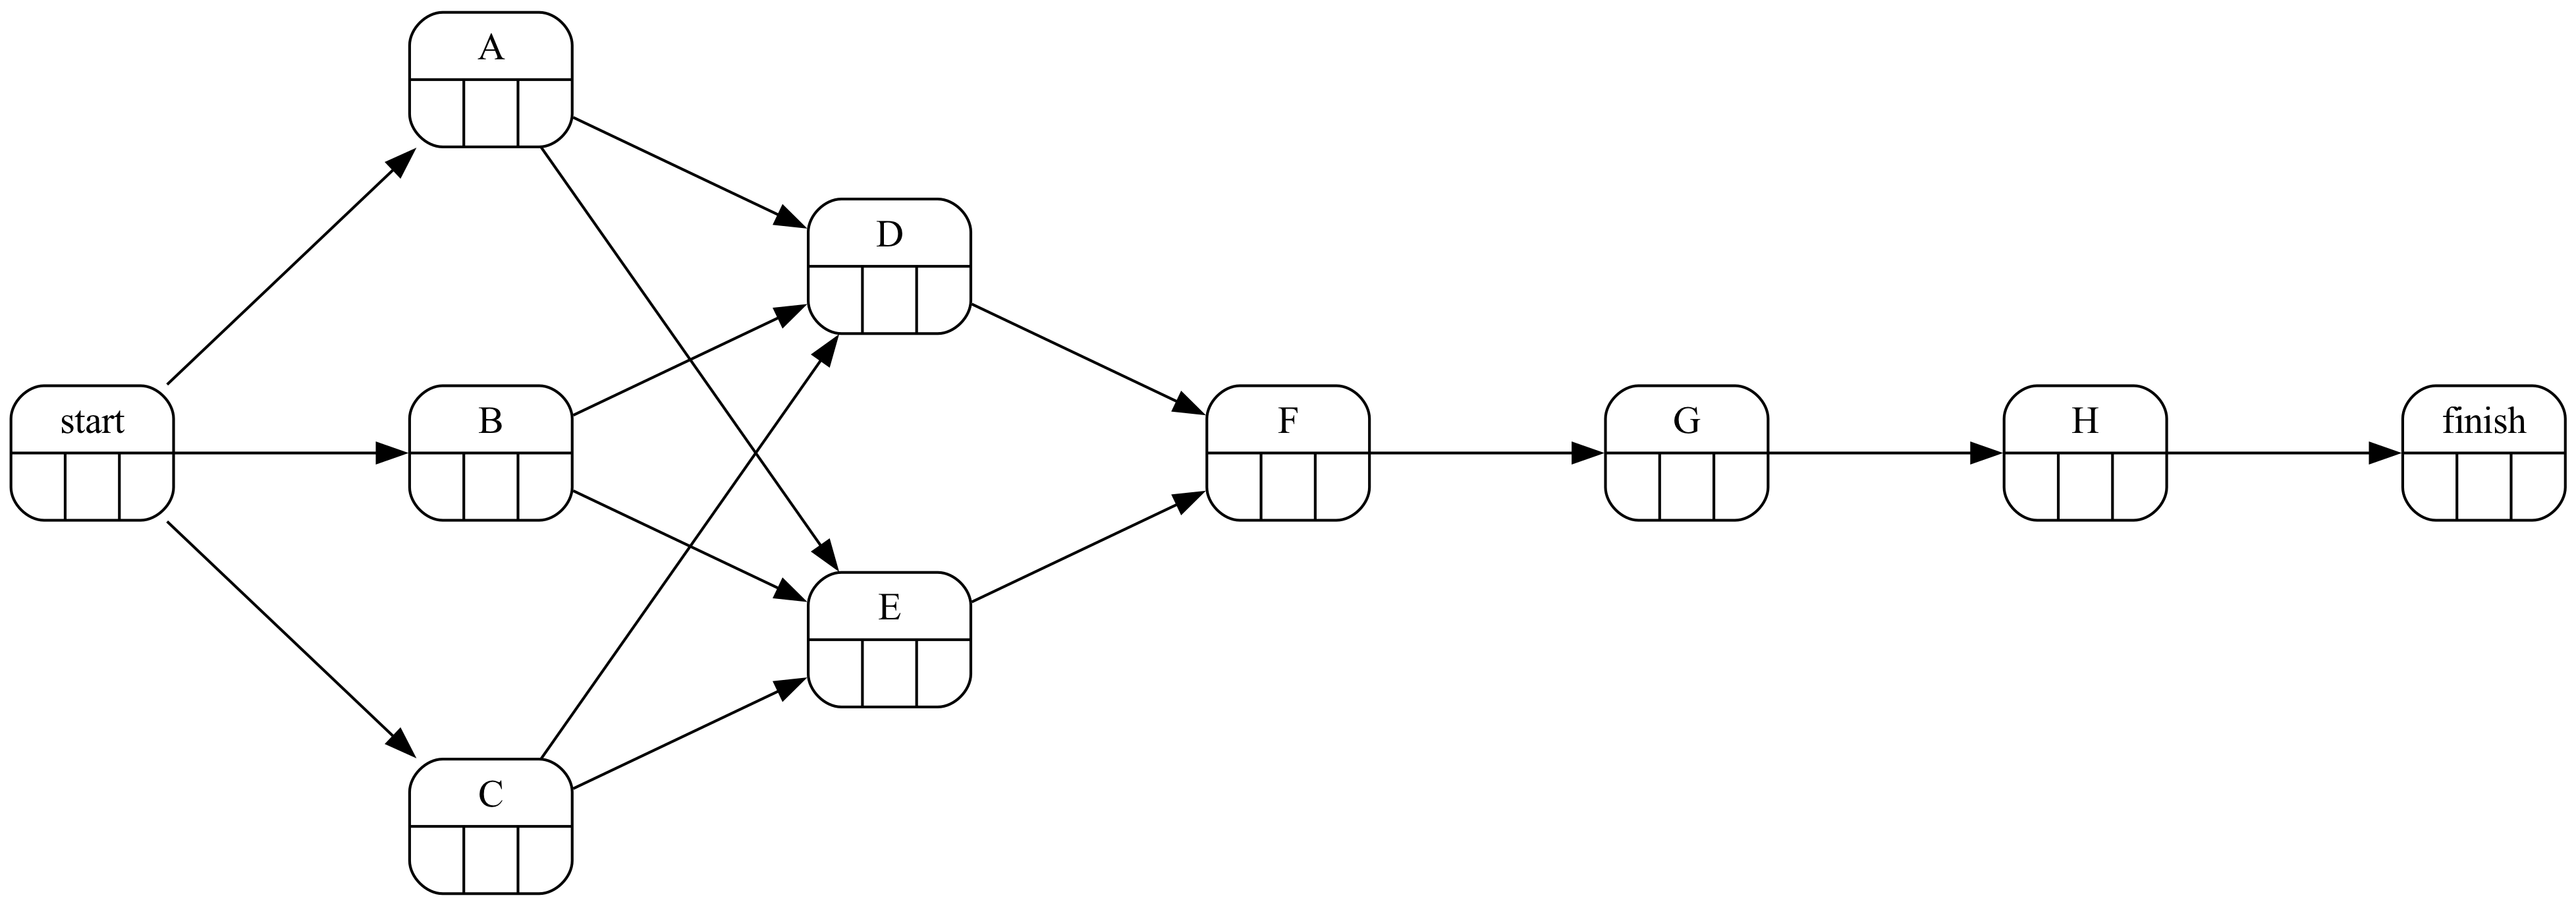

In [8]:
#| fig-cap: "Grafo Roy del proyecto"
#| label: fig-roy
proyecto.roy(ranksep=1.2, nodesep=1.2)

Recorriendo las actividades en un orden en que cada una aparece después de sus predecesoras (orden topológico):

In [9]:
G = nx.DiGraph([(p, a) for a, ps in predecesoras.items() for p in ps])
G.add_nodes_from(datos_proyecto.index)
orden = list(nx.topological_sort(G))
ES, EF, filas = {}, {}, []
for a in orden:
    ps = sorted(predecesoras[a])
    ES[a] = max((EF[p] for p in ps), default=0)
    EF[a] = ES[a] + int(duracion[a])
    filas.append({'actividad': a, 'predecesoras (EF)': ', '.join(f'{p} ({EF[p]})' for p in ps) or '—',
                  'ES = máx': ES[a], 'duración': int(duracion[a]), 'EF = ES + d': EF[a]})
pd.DataFrame(filas).set_index('actividad')

,predecesoras (EF),ES = máx,duración,EF = ES + d
actividad,,,,
C,—,0,1,1
B,—,0,6,6
A,—,0,4,4
D,"A (4), B (6), C (1)",6,6,12
E,"A (4), B (6), C (1)",6,3,9
F,"D (12), E (9)",12,5,17
G,F (17),17,4,21
H,G (21),21,6,27


## Apartado 2

In [10]:
display(Markdown(pregunta_2))

2. Calcule del mismo modo, de atrás hacia delante, los fines e inicios más tardíos.  

In [11]:
duracion_proyecto = max(EF.values())
LS, LF, filas = {}, {}, []
for a in reversed(orden):
    ss = sucesoras[a]
    LF[a] = min((LS[s] for s in ss), default=duracion_proyecto)
    LS[a] = LF[a] - int(duracion[a])
    filas.append({'actividad': a, 'sucesoras (LS)': ', '.join(f'{s} ({LS[s]})' for s in ss) or '—',
                  'LF = mín': LF[a], 'duración': int(duracion[a]), 'LS = LF − d': LS[a]})
pd.DataFrame(filas).set_index('actividad')

,sucesoras (LS),LF = mín,duración,LS = LF − d
actividad,,,,
H,—,27,6,21
G,H (21),21,4,17
F,G (17),17,5,12
E,F (12),12,3,9
D,F (12),12,6,6
A,"D (6), E (9)",6,4,2
B,"D (6), E (9)",6,6,0
C,"D (6), E (9)",6,1,5


In [12]:
calendario = proyecto.calendar(duracion)
coincide = all(calendario.loc[a, 'inicio_mas_temprano'] == ES[a] and calendario.loc[a, 'inicio_mas_tardio'] == LS[a] for a in orden)
Markdown(f'La duración del proyecto es {duracion_proyecto} días. El cálculo coincide con el de la librería: {coincide}.')

La duración del proyecto es 27 días. El cálculo coincide con el de la librería: True.

## Apartado 3

In [13]:
display(Markdown(pregunta_3))

3. Para cada actividad con varias predecesoras indique cuál de ellas fija su inicio más temprano (la *predecesora dominante*). En particular, ¿qué predecesora de E manda?  

In [14]:
dominantes = {}
for a in datos_proyecto.index:
    ps = sorted(predecesoras[a])
    if len(ps) >= 2:
        maximo = max(EF[p] for p in ps)
        dominantes[a] = ', '.join(p for p in ps if EF[p] == maximo)
pd.Series(dominantes).to_frame('predecesora dominante')

,predecesora dominante
D,B
E,B
F,D


La predecesora dominante de E es B: su fin más temprano es el mayor de entre las predecesoras y por tanto el que fija el inicio de E. Las demás predecesoras terminan antes y tienen margen (holgura libre) respecto a E.

## Apartado 4

In [15]:
display(Markdown(pregunta_4))

4. Si se quisiera adelantar el inicio de E un día, ¿qué actividad habría que acortar? ¿Serviría de algo acortar sus otras predecesoras?  

In [16]:
objetivo, dominante = 'E', 'B'
otras = [p for p in sorted(predecesoras[objetivo]) if p != dominante]
margen = {p: EF[dominante] - EF[p] for p in otras}
d2 = duracion.copy(); d2[dominante] -= 1
ES_nuevo = int(proyecto.calendar(d2).loc[objetivo, 'inicio_mas_temprano'])
Markdown(f'''Para adelantar {objetivo} hay que acortar {dominante} (o alguna de sus antecesoras en la cadena que la hace llegar la última): acortándola un día, {objetivo} empieza en {ES_nuevo} en vez de {ES[objetivo]}. Acortar {", ".join(otras)} no sirve: terminan {", ".join(f"{p} {m} día(s)" for p, m in margen.items())} antes que {dominante} y su holgura sólo aumentaría. Sólo cuando {dominante} se acorte tanto que otra predecesora pase a ser la última cambiará la dominante.''')

Para adelantar E hay que acortar B (o alguna de sus antecesoras en la cadena que la hace llegar la última): acortándola un día, E empieza en 5 en vez de 6. Acortar A, C no sirve: terminan A 2 día(s), C 5 día(s) antes que B y su holgura sólo aumentaría. Sólo cuando B se acorte tanto que otra predecesora pase a ser la última cambiará la dominante.